# Figure 6 · Reconstruction accuracy and spatial structure

One three-panel figure in a single row combines the former `06`, `06b` and `06c` notebooks:
from left to right: source and outside-source RMSE, power relative to observed
JWST, and signed Fourier correlation with JWST. Filled circles mark
source RMSE; open squares mark outside-source RMSE on the same linear axis. Spectral panels use solid
source curves and dashed outside-source curves, with the same method colors.

Read only the frozen validation diagnostics: benchmark v03, whole-cutout spectra
v01, and strict-source spectra v01. No training, inference, or external upload.
The figure uses all six existing methods and the Figure 5 checkpoints: epoch 49
for ResNet/ResNet-D5 and epoch 35 for diffusion, with 50 sampling steps. The
single diffusion draw has a fixed seed; the mean averages three linear images.

RMSE retains all **2,118** objects. Source spectra retain **1,363** complete
cutouts; outside-source spectra retain **1,356** with sufficient window area.
These populations are explicit rather than silently intersected or changed.
Uncertainties are the saved 95% paired spatial-block bootstrap intervals.

MAE and original inference timings appear in a supplementary table below.
Optional source-boundary sensitivity plots are controlled by `SHOW_CHECKS`.
The three original notebooks and their diagnostic plots remain archived in
`revisions/` and `exports/`; this is the only active Figure 6 notebook.

Style revision v07: shared scientific figure style, Matisse-inspired method
colors with redundant line patterns and redundant symbols. Frozen inputs, populations, and numerical values
are retained; the previous executed notebook is archived in `revisions/style_before_v01/`.


In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from IPython.display import display

here = Path.cwd()
workspace = here if (here/'figure_utils.py').exists() else here/'paper_figures'
if str(workspace) not in sys.path:
    sys.path.insert(0, str(workspace))
from figure_utils import ROOT, FIGURES, COLORS, style, read_json, sha, export
%matplotlib inline
style(fontsize=10)
VERSION = 'v07'
SHOW_CHECKS = False
names = ['bilinear', 'bicubic', 'diffusion', 'diffusion_mean3', 'legacy', 'direct5']
labels = {'bilinear':'Bilinear', 'bicubic':'Bicubic', 'diffusion':'Diffusion (1 sample)',
          'diffusion_mean3':'Diffusion (mean of 3)', 'legacy':'ResNet', 'direct5':'ResNet-D5'}
colors = COLORS.copy()
benchmark_path = FIGURES/'inputs/model_benchmark_v03.json'
whole_path = FIGURES/'inputs/spatial_spectra_v01.json'
source_path = FIGURES/'inputs/spatial_spectra_source_v01.json'
input_paths = [benchmark_path, whole_path, source_path]
benchmark, whole_spectra, source_spectra = map(read_json, input_paths)
from figure_utils import MARKERS, INK, GRID, ESTIMATOR_COLORS, finish_axes


In [2]:
# Check completion, shared provenance, populations, and the actual plotted arrays.
for record in [benchmark, whole_spectra, source_spectra]:
    assert record['complete'] and record['local_only'] and record['split'] == 'validation'
assert benchmark['units'] == 'MJy/sr'
object_ids = benchmark['object_ids']
assert object_ids and len(set(object_ids)) == len(object_ids)
mask_path = ROOT/benchmark['source_mask_path']
assert sha(mask_path) == benchmark['source_mask_sha256']
mask_protocol = benchmark['source_mask_metadata']['protocol']
primary = next(r for r in benchmark['source_regions']
               if r['threshold_sigma'] == mask_protocol['primary_threshold_sigma'])
rmse_regions = {'source':primary['source'], 'outside':primary['background']}
for region in rmse_regions.values():
    assert region['object_ids'] == object_ids
    for name in names:
        assert benchmark['methods'][name]['object_ids'] == object_ids
        for metric in ['mae_mjy_sr', 'rmse_mjy_sr']:
            values = np.asarray(region['methods'][name][metric])
            assert values.shape == (len(object_ids),) and np.isfinite(values).all()
            assert (values >= 0).all()
            np.testing.assert_allclose(values.mean(), region['summary']['methods'][name][metric]['mean'])
for record in [whole_spectra, source_spectra]:
    assert record['object_ids'] == object_ids and record['methods'] == names
    assert record['inputs'][str(benchmark_path.relative_to(ROOT))] == sha(benchmark_path)
    assert record['inputs'][benchmark['source_mask_path']] == benchmark['source_mask_sha256']
    assert record['inputs'][benchmark['prediction_cache']['path']] == benchmark['prediction_cache']['sha256']
    assert sha(ROOT/record['arrays_path']) == record['arrays_sha256']
assert whole_spectra['radial_edges_cycles_per_pixel'] == source_spectra['radial_edges_cycles_per_pixel']
assert whole_spectra['frequencies_cycles_per_pixel'] == source_spectra['frequencies_cycles_per_pixel']
assert whole_spectra['summaries']['background'] == source_spectra['summaries']['background']
spectral_regions = {'source':source_spectra['summaries']['source3'],
                    'outside':source_spectra['summaries']['background']}
assert spectral_regions['source']['object_ids'] == whole_spectra['summaries']['tukey50']['object_ids']
assert set(spectral_regions['outside']['object_ids']) <= set(spectral_regions['source']['object_ids']) <= set(object_ids)
nrings = len(source_spectra['radial_edges_cycles_per_pixel']) - 1
frequency = np.asarray(source_spectra['frequencies_cycles_per_pixel'][:nrings])
# Measured median target scale; axis conversion only, not a PSF correction.
pixel_scale = 0.05934367
scale = pixel_scale/frequency
native_nyquist_scale = 10*pixel_scale
for region in spectral_regions.values():
    assert len(region['object_ids']) == region['objects']
    for name in names:
        for metric in ['log_power_ratio', 'correlation']:
            record = region['methods'][name][metric]
            values = np.asarray(record['mean'][:nrings])
            ci = np.asarray(record['ci95'][:nrings])
            assert values.shape == (nrings,) and ci.shape == (nrings, 2)
            assert np.isfinite(values).all() and np.isfinite(ci).all()
            assert (ci[:, 0] <= ci[:, 1]).all()
print(f"RMSE: {len(object_ids):,}; source spectra: {spectral_regions['source']['objects']:,}; "
      f"outside-source spectra: {spectral_regions['outside']['objects']:,} objects.")
print('Frozen input hashes, method identities, populations, and plotted summaries verified.')

RMSE: 2,118; source spectra: 1,363; outside-source spectra: 1,356 objects.
Frozen input hashes, method identities, populations, and plotted summaries verified.


## Three panels in one row

The left panel combines source and outside-source RMSE on the same linear axis,
with filled circles and open squares, respectively. Both use the same method
rows and saved confidence intervals. The middle and right panels share angular scale
(coarse to fine), with solid source curves and dashed outside-source curves.
Each region is normalized to JWST measured through that same region's window.
Shading and whiskers show saved 95% intervals. All six methods are retained;
closely overlapping curves are not displaced. The dotted vertical line marks
native NISP pixel Nyquist, not an inferred resolution.

Panel titles and footer notes are omitted; sample counts, intervals and the
Nyquist/reference qualifications are retained in the caption.

findfont: Font family ['cursive'] not found. Falling back to DejaVu Sans.


findfont: Generic family 'cursive' not found because none of the following families were found: Apple Chancery, Textile, Zapf Chancery, Sand, Script MT, Felipa, Comic Neue, Comic Sans MS, cursive


Exported: fig06_model_comparison_v07.pdf, fig06_model_comparison_v07.svg, fig06_model_comparison_v07.png


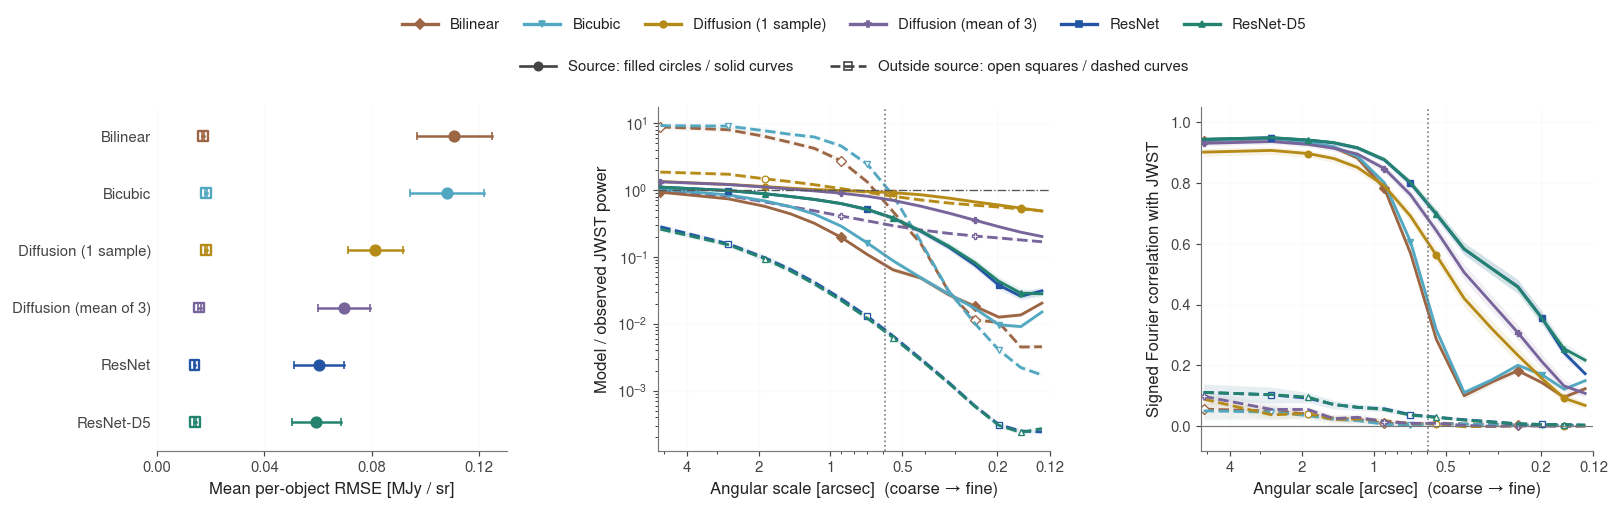

In [3]:
def scale_axis(ax):
    ax.set_xscale('log')
    ax.set_xlim(scale[0]*1.02, scale[-1]/1.02)
    ticks = [4, 2, 1, .5, .2, .12]
    ax.set_xticks(ticks, [str(t) for t in ticks])
    ax.set_xlabel('Angular scale [arcsec]  (coarse → fine)')
    ax.axvline(native_nyquist_scale, color='#777777', ls=':', lw=1)
    ax.grid(alpha=.15)

fig, axes = plt.subplots(1, 3, figsize=(14.0, 4.4),
                         gridspec_kw={'width_ratios':[1.0, 1.12, 1.12]})
ax = axes[0]
for region_key, marker in [('source', 'o'), ('outside', 's')]:
    summary = rmse_regions[region_key]['summary']['methods']
    for i, name in enumerate(names):
        record = summary[name]['rmse_mjy_sr']
        lo, hi = record['ci95']
        ax.plot([lo, hi], [i, i], color=colors[name], lw=1.5, zorder=2)
        ax.plot([lo, hi], [i, i], '|', color=colors[name], ms=5, zorder=2)
        ax.scatter(record['mean'], i, s=35, marker=marker,
                   facecolors=colors[name] if region_key == 'source' else 'none',
                   edgecolors=colors[name], linewidths=1.4, zorder=3)
ax.set_yticks(np.arange(len(names)), [labels[name] for name in names])
ax.set_ylim(len(names)-.5, -.5)
ax.set_xlim(left=0)
ax.set_xticks([0, .04, .08, .12])
ax.set_xlabel('Mean per-object RMSE [MJy / sr]')
ax.tick_params(axis='y', length=0)
ax.spines['left'].set_visible(False)
ax.grid(axis='x', alpha=.18)

for region_key, linestyle, alpha in [('outside', '--', .055), ('source', '-', .10)]:
    for name in names:
        for ax, metric in zip(axes[1:], ['log_power_ratio', 'correlation']):
            record = spectral_regions[region_key]['methods'][name][metric]
            y = np.asarray(record['mean'][:nrings])
            ci = np.asarray(record['ci95'][:nrings])
            if metric == 'log_power_ratio':
                y, ci = 10**y, 10**ci
            ax.plot(scale,y,color=colors[name],ls=linestyle,lw=1.7,
                    marker=MARKERS[name],markevery=(names.index(name)%3,5),ms=4,
                    mfc=colors[name] if region_key=='source' else 'white',mew=.8)
            ax.fill_between(scale, ci[:, 0], ci[:, 1], color=colors[name], alpha=alpha, lw=0)
axes[1].set_yscale('log')
axes[1].axhline(1, color='#555555', ls='-.', lw=.8)
axes[1].set_ylabel('Model / observed JWST power')
axes[2].set_ylim(-.08, 1.05)
axes[2].axhline(0, color='#777777', lw=.7)
axes[2].set_ylabel('Signed Fourier correlation with JWST')
for ax in axes[1:]:
    scale_axis(ax)
method_handles = [Line2D([], [], color=colors[n],lw=2,marker=MARKERS[n],ms=4,label=labels[n]) for n in names]
fig.legend(handles=method_handles, loc='upper center', bbox_to_anchor=(.55, .995),
           ncol=6, frameon=False, columnspacing=1.6)
region_handles = [Line2D([], [], color='#444444', lw=1.6, ls='-', marker='o',
                        markersize=5, label='Source: filled circles / solid curves'),
                  Line2D([], [], color='#444444', lw=1.6, ls='--', marker='s',
                        markerfacecolor='none', markersize=5,
                        label='Outside source: open squares / dashed curves')]
fig.legend(handles=region_handles, loc='upper center', bbox_to_anchor=(.55, .915),
           ncol=2, frameon=False, columnspacing=2.4)
fig.subplots_adjust(left=.135, right=.99, top=.80, bottom=.15, wspace=.40)
paths = export(fig, f'fig06_model_comparison_{VERSION}', '06_model_comparison.ipynb',
    input_paths, dict(methods=names, panels=['source_and_outside_rmse', 'power_ratio', 'signed_fourier_correlation'],
    layout='one row, three columns; no panel titles or footer notes', rmse_markers={'source':'filled circle', 'outside_source':'open square'},
    rmse_objects=len(object_ids), source_spectral_objects=spectral_regions['source']['objects'],
    outside_spectral_objects=spectral_regions['outside']['objects'],
    source_mask=mask_protocol, source_window=source_spectra['main_window'],
    outside_window=source_spectra['background'], pixel_scale_arcsec=pixel_scale,
    power=source_spectra['power'], correlation=source_spectra['correlation'],
    rmse_intervals=benchmark['summary']['rule'], spectral_intervals=source_spectra['bootstrap'],
    region_styles={'source':'solid', 'outside_source':'dashed'}),
    status='Local validation draft: combined source/outside RMSE, power and signed Fourier correlation')
plt.show()

## Working caption

**Reconstruction accuracy and spatial structure in reference-defined source and
outside-source regions.** The left panel shows mean per-object RMSE against
JWST F115W in signed, sky-subtracted MJy/sr for all 2,118 validation objects.
RMSE is computed within each region before averaging objects with equal weight;
filled circles mark sources and open squares mark outside-source pixels on a shared linear axis. Every method uses the same valid
pixels in the central 105 × 105 target-pixel field (approximately 6.3 arcsec).
Source masks include all detected neighbours: smooth the full JWST image with
a Gaussian of sigma 1 target pixel, detect at least 10 connected pixels above
the clipped local sky median plus twice the smoothed sky standard deviation,
fill holes, and dilate by 3 pixels. Sky statistics use radii 70–95 target pixels.
Smoothing and sky estimation define masks only; errors use the original images.

The middle and right panels show the geometric mean per-object model/JWST power ratio and
the arithmetic mean signed annular Fourier correlation,
$r=\mathrm{Re}\langle F_{\rm model}F_{\rm JWST}^{*}\rangle/
\sqrt{\langle|F_{\rm model}|^2\rangle\langle|F_{\rm JWST}|^2\rangle}$.
Solid curves use source pixels in 1,363 completely valid cutouts; dashed curves
use outside-source pixels in the 1,356 of those cutouts with sufficient outside
window area. Each model and reference share exactly the same region window.
Subtract each image's own window-weighted mean, apply a 3-pixel inward boundary
taper and an outer Tukey window (alpha 0.5), and normalize Fourier amplitudes by
the square root of the window energy. Source-window weights are exactly zero
outside the source mask; outside-source weights are zero within it.

Whiskers and shaded bands show 95% intervals from 2,000 paired spatial-block
bootstrap resamples over 18 blocks. Colors identify methods; diffusion uses one
fixed realization or the linear mean of three. Checkpoints match Figure 5
(ResNet and ResNet-D5 epoch 49; diffusion epoch 35 with 50 sampling steps).
The dotted line marks the NISP pixel Nyquist wavelength, approximately 0.593 arcsec,
rather than an effective resolution. Observed JWST spectra retain noise; no noise
subtraction, PSF correction, or window deconvolution is applied. The masks derive
from the noisy reference, their irregular boundaries mix Fourier modes, and
outside-source pixels can contain faint undetected light. Greater power agreement
alone does not establish faithful recovery of individual morphological features.

The original ResNet checkpoint is retained as the main paper model. Independent
training seeds 20261016, 20261018 and 20261019 yield selected-checkpoint source
RMSE of 0.0601735, 0.0601034 and 0.0600667 MJy/sr, respectively. Their comparison
is retained in the diagnostic archive; these repetitions do not replace the
main curve with a selected seed or an ensemble. The plotted spatial-block
intervals do not include training-seed variation. Matched continuation tests
gave a source/outside-source trade-off and no clear shape improvement, so the
original epoch-49 checkpoint remains fixed for subsequent held-out evaluation.
All results shown here remain validation results.


## Supplementary numerical table

MAE and original device-resident inference times are retained here rather than
occupying main-figure panels. Timings use the original batch-eight NVIDIA L40S
benchmark: medians and repeat ranges, **not confidence intervals**. No new timing
or model evaluation is performed. The table also records the displayed RMSE.

In [4]:
rows = []
for name in names:
    timing = benchmark['methods'][name]['timing']
    row = {'Method':labels[name]}
    for key, label in [('source', 'Source'), ('outside', 'Outside source')]:
        for metric, short in [('mae_mjy_sr', 'MAE'), ('rmse_mjy_sr', 'RMSE')]:
            row[f'{label} {short} [MJy/sr]'] = rmse_regions[key]['summary']['methods'][name][metric]['mean']
    row['Median ms/object'] = timing['median_ms_per_object']
    row['Min ms/object'] = timing['min_ms_per_object']
    row['Max ms/object'] = timing['max_ms_per_object']
    rows.append(row)
display(pd.DataFrame(rows).set_index('Method'))

,Source MAE [MJy/sr],Source RMSE [MJy/sr],Outside source MAE [MJy/sr],Outside source RMSE [MJy/sr],Median ms/object,Min ms/object,Max ms/object
Method,,,,,,,
Bilinear,0.028902,0.110684,0.013389,0.017103,0.003146,0.003004,0.005248
Bicubic,0.028897,0.107888,0.014279,0.018246,0.005781,0.005313,0.006441
Diffusion (1 sample),0.026297,0.081233,0.013916,0.018152,125.307236,125.097991,125.540099
Diffusion (mean of 3),0.022781,0.069622,0.012050,0.015720,377.986223,377.416664,378.333866
ResNet,0.020306,0.060173,0.010863,0.013957,0.471671,0.470387,0.473218
ResNet-D5,0.020247,0.059152,0.010860,0.013985,0.638244,0.634341,0.642199


## Optional boundary checks and archived diagnostics

Set `SHOW_CHECKS = True` to inspect how source-boundary widths of 1, 3 and 5 pixels
change the paired diffusion minus ResNet-D5 differences, alongside the whole-cutout
control. The finest bins are sensitive to masking and should not be interpreted
as an intrinsic resolution measurement.

All previous supplementary work remains available:
- [Accuracy, error distributions, threshold checks and mask examples](revisions/06_model_comparison_v03_before_consolidation.ipynb).
- [Whole-cutout spectra, outer-window checks and outside-source controls](revisions/06b_spatial_structure_v01_before_consolidation.ipynb).
- [Strict-source spectra, reference/background contrast and boundary checks](revisions/06c_source_spatial_structure_v01_before_consolidation.ipynb).

These are frozen historical snapshots, including their original outputs and export
names. The current figure is produced only by this notebook; old exports are
preserved for comparison. Background contrast remains a diagnostic proxy, not
calibrated signal-to-noise. The held-out test set is not evaluated.

In [5]:
if SHOW_CHECKS:
    check_fig, check_axes = plt.subplots(1, 2, figsize=(11, 4.3))
    cases = {'source3':('Source: 3-pixel taper', '#0072B2'),
             'source1':('Source: 1-pixel taper', '#D55E00'),
             'source5':('Source: 5-pixel taper', '#009E73'),
             'whole':('Whole cutout', '#8B5DA8')}
    for case, (label, color) in cases.items():
        paired = source_spectra['paired_diffusion_vs_resnet']['direct5'][case]
        for ax, metric in zip(check_axes, ['absolute_log_power_error_difference', 'correlation_difference']):
            record = paired[metric]
            y = np.asarray(record['mean'][:nrings])
            ci = np.asarray(record['ci95'][:nrings])
            ax.plot(scale, y, color=color, label=label)
            ax.fill_between(scale, ci[:, 0], ci[:, 1], color=color, alpha=.1, lw=0)
    check_axes[0].set_ylabel('Diffusion − ResNet-D5: |log₁₀ power ratio|')
    check_axes[1].set_ylabel('Diffusion − ResNet-D5: correlation')
    check_axes[0].set_title('Power mismatch (negative favors diffusion)')
    check_axes[1].set_title('Correlation (positive favors diffusion)')
    for ax in check_axes:
        scale_axis(ax)
        ax.axhline(0, color='#555555', ls='--', lw=.8)
    handles, legend_labels = check_axes[0].get_legend_handles_labels()
    check_fig.legend(handles, legend_labels, loc='upper center', ncol=4, frameon=False)
    check_fig.subplots_adjust(left=.08, right=.99, top=.80, bottom=.16, wspace=.32)
    plt.show()

## Exploratory PSNR and SSIM — separate from the paper figure

Measured from the frozen v03 prediction cache for all 2,118 validation objects
using `code/analyze_psnr_ssim.py`. This section adds a separate review plot; the
three-panel Figure 6 above retains its current content.

Each object's dynamic range is **max minus min of observed JWST over all common-valid
pixels**, shared by every method and region. Images retain signed linear MJy/sr;
there is no clipping, separate image normalization, additive offset, or noise
subtraction. PSNR is `20 log10(range / regional RMSE)`, averaged in dB across
objects, rather than computed from mean RMSE.

SSIM uses a uniform **7 × 7** window with sample covariance and constants
K1 = 0.01, K2 = 0.03. Every retained window lies entirely inside the selected
region and valid image support. Average its SSIM map values within each object,
then average objects equally. The source and outside-source images are **not
zero-masked** before SSIM. The source mask includes neighbours and is the same
frozen 2-sigma JWST mask used above. All objects retain at least one full window
in every region. SSIM consequently describes region interiors; PSNR uses all
regional pixels. The exact counts and protocol are saved in the input bundle.

Whiskers are 95% paired spatial-block intervals (2,000 resamples over 18 blocks).
Both scores increase with similarity. The range depends on noisy reference
extrema, and SSIM depends on its window and stabilizing constants; signed
near-zero sky levels influence its luminance term. These are observed-image
similarity diagnostics, not a noise-free morphology measure. Their values are
not directly interchangeable with historical normalized-image results.

In [6]:
psnr_ssim_path = FIGURES/'inputs/psnr_ssim_v01.json'
psnr_ssim_ready = psnr_ssim_path.exists()
if psnr_ssim_ready:
    quality = read_json(psnr_ssim_path)
    assert quality['complete'] and quality['local_only'] and quality['split'] == 'validation'
    assert quality['object_ids'] == object_ids and quality['methods'] == names
    assert quality['inputs'][str(benchmark_path.relative_to(ROOT))] == sha(benchmark_path)
    assert quality['inputs'][benchmark['prediction_cache']['path']] == benchmark['prediction_cache']['sha256']
    assert quality['inputs'][benchmark['source_mask_path']] == benchmark['source_mask_sha256']
    assert sha(ROOT/quality['arrays_path']) == quality['arrays_sha256']
    quality_rows = []
    for name in names:
        row = {'Method':labels[name]}
        for region, title in [('all', 'All valid'), ('source', 'Source'), ('outside', 'Outside source')]:
            for metric, short in [('psnr_db', 'PSNR [dB]'), ('ssim', 'SSIM')]:
                row[f'{title}: {short}'] = quality['summary'][region]['methods'][name][metric]['mean']
        quality_rows.append(row)
    display(pd.DataFrame(quality_rows).set_index('Method').round(4))
else:
    print('Optional PSNR/SSIM results are missing. Run code/analyze_psnr_ssim.py once from the repository root.')

,All valid: PSNR [dB],All valid: SSIM,Source: PSNR [dB],Source: SSIM,Outside source: PSNR [dB],Outside source: SSIM
Method,,,,,,
Bilinear,29.5105,0.4684,25.3143,0.5465,35.3892,0.4626
Bicubic,29.4481,0.4518,25.5390,0.5607,34.8225,0.4423
Diffusion (1 sample),30.3401,0.4941,26.1628,0.5326,34.9053,0.5022
Diffusion (mean of 3),31.7916,0.5420,27.6462,0.5915,36.2264,0.5494
ResNet,32.8316,0.5835,28.6715,0.6184,37.2174,0.5932
ResNet-D5,32.8788,0.5838,28.7222,0.6183,37.2185,0.5935


Exported: fig06_psnr_ssim_v07.pdf, fig06_psnr_ssim_v07.svg, fig06_psnr_ssim_v07.png


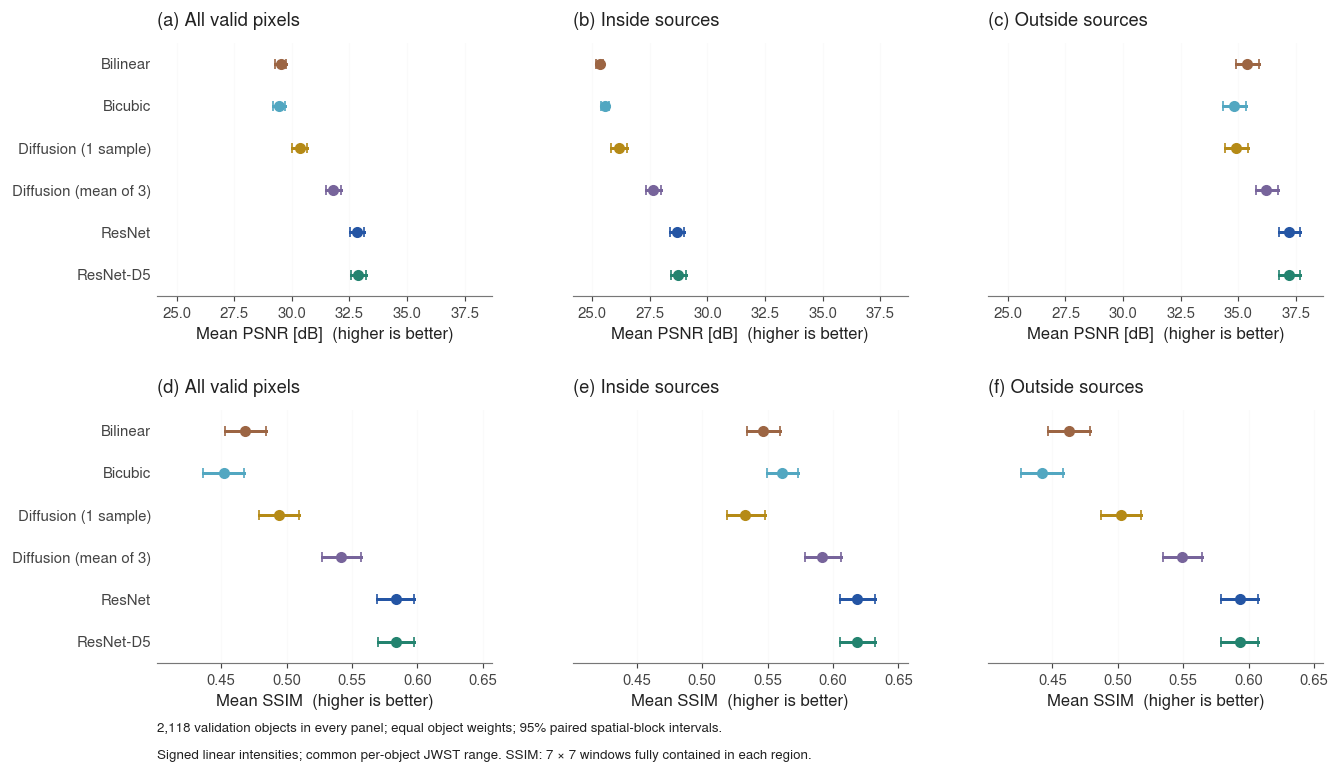

In [7]:
if psnr_ssim_ready:
    quality_fig, quality_axes = plt.subplots(2, 3, figsize=(12.0, 6.8), sharey=True)
    region_titles = [('all', 'All valid pixels'), ('source', 'Inside sources'), ('outside', 'Outside sources')]
    for col, (region, title) in enumerate(region_titles):
        for row, (metric, xlabel) in enumerate([('psnr_db', 'Mean PSNR [dB]'), ('ssim', 'Mean SSIM')]):
            ax = quality_axes[row, col]
            for i, name in enumerate(names):
                record = quality['summary'][region]['methods'][name][metric]
                lo, hi = record['ci95']
                ax.plot([lo, hi], [i, i], color=colors[name], lw=1.8)
                ax.plot([lo, hi], [i, i], '|', color=colors[name], ms=6)
                ax.scatter(record['mean'], i, color=colors[name], s=32, zorder=3)
            ax.set_yticks(np.arange(len(names)), [labels[name] for name in names])
            ax.set_ylim(len(names)-.5, -.5)
            ax.set_xlabel(xlabel+'  (higher is better)')
            ax.set_title(f'({chr(97+row*3+col)}) {title}', loc='left', pad=10)
            ax.grid(axis='x', alpha=.18)
            ax.tick_params(axis='y', length=0)
            ax.spines['left'].set_visible(False)
    # Shared metric axes across regions make regional values directly comparable.
    all_ci = [quality['summary'][r]['methods'][name]['psnr_db']['ci95']
              for r, _ in region_titles for name in names]
    lower, upper = np.min(all_ci), np.max(all_ci)
    for ax in quality_axes[0]:
        ax.set_xlim(lower-1, upper+1)
    ssim_ci = [quality['summary'][r]['methods'][name]['ssim']['ci95']
               for r, _ in region_titles for name in names]
    for ax in quality_axes[1]:
        ax.set_xlim(np.min(ssim_ci)-.025, np.max(ssim_ci)+.025)
    quality_fig.subplots_adjust(left=.18, right=.99, top=.91, bottom=.15, wspace=.24, hspace=.45)
    quality_fig.text(.18, .065, '2,118 validation objects in every panel; equal object weights; 95% paired spatial-block intervals.', fontsize=8)
    quality_fig.text(.18, .032, 'Signed linear intensities; common per-object JWST range. SSIM: 7 × 7 windows fully contained in each region.', fontsize=8)
    export(quality_fig, f'fig06_psnr_ssim_{VERSION}', '06_model_comparison.ipynb',
           [psnr_ssim_path], dict(methods=names, regions=quality['regions'], objects=len(object_ids),
           intensity=quality['intensity'], data_range=quality['data_range'],
           psnr=quality['psnr'], ssim=quality['ssim'], bootstrap=quality['bootstrap']),
           status='Local exploratory PSNR and SSIM; supplementary review plot, not installed in manuscript')
    plt.show()

## Manuscript installation and reproducibility

The approved v06 PDF is installed as `paper/figs/model_comparison_v06.pdf`; its
three-panel artwork and underlying predictions are unchanged. The manuscript
caption and regional measurement definitions are in `paper/survey_enhancements.tex`.
The independent-seed plot and selected/final-checkpoint tables are included via
`paper/resnet_validation_appendix.tex`. Numerical provenance is frozen in
`paper/diagnostics/resnet_model_selection_v01.json`.

The historical export sidecar describes the original v06 rendering; the
pre-install notebook is archived in `revisions/`. The extra caption text here
does not change the original plot. The exploratory PSNR/SSIM plot remains
separate from the main paper figure.
